# # Tugas — CNN CIFAR-10 > 80% dan CNN MNIST
# Bagian 1: memodifikasi CNN praktikum 2 (subset CIFAR-10: 20.000 latih / 1.967 uji, 32x32) sampai akurasi uji > 80%.
# Empat varian diuji dengan angka nyata:
#
# | Varian | Perubahan |
# |---|---|
# | V1 | baseline 3 Conv + Dense (seperti praktikum 2), 4 epoch |
# | V2 | + Dropout 0.4, 5 epoch |
# | V3 | konvolusi ganda + BatchNormalization + augmentasi (flip/geser/zoom), 8 epoch |
# | V4 | transfer learning EfficientNetB0 (ImageNet, base dibekukan) di 128x128 + head Dense |
#
# V1–V3 dilatih dari nol (CPU-only), V4 memakai fitur pra-latih karena CNN from-scratch butuh puluhan
# epoch / GPU untuk melewati 80% pada data sekecil ini. Semua angka berasal dari eksekusi nyata.
#
# Bagian 2: CNN MNIST (`keras.datasets.mnist`, 60.000 latih / 10.000 uji, cache lokal) + contoh salah klasifikasi.

In [1]:
import os
__file__ = os.path.abspath("tugas_cnn.ipynb")

import gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
                                     BatchNormalization, Input, RandomFlip,
                                     RandomTranslation, RandomZoom, Activation,
                                     GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42); np.random.seed(42)

BASE = Path(__file__).resolve().parent.parent
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

In [2]:
d = np.load(BASE / "data" / "cifar10_subset.npz")
x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]
xt, xe = x_train / 255.0, x_test / 255.0
yt, ye = to_categorical(y_train, 10), to_categorical(y_test, 10)
print("latih:", xt.shape, "uji:", xe.shape)

latih: (20000, 32, 32, 3) uji: (1967, 32, 32, 3)


# ## Bagian 1 — Varian V1..V3 (dilatih dari nol)

In [3]:
def bangun(varian: str) -> Sequential:
    lapis = [Input((32, 32, 3))]
    if varian == "V3":
        lapis += [RandomFlip("horizontal"),
                  RandomTranslation(0.1, 0.1, fill_mode="nearest"),
                  RandomZoom(0.1, 0.1, fill_mode="nearest"),
                  Conv2D(32, 3, padding="same", activation="relu"), BatchNormalization(),
                  Conv2D(32, 3, padding="same", activation="relu"), MaxPooling2D(2, 2),
                  Conv2D(64, 3, padding="same", activation="relu"), BatchNormalization(),
                  Conv2D(64, 3, padding="same", activation="relu"), MaxPooling2D(2, 2)]
    else:
        lapis += [Conv2D(32, 3, padding="same", activation="relu"),
                  Conv2D(32, 3, padding="same", activation="relu"), MaxPooling2D(2, 2),
                  Conv2D(64, 3, padding="same", activation="relu"), MaxPooling2D(2, 2)]
    lapis += [Flatten(),
              Dropout(0.4) if varian != "V1" else Activation("linear"),
              Dense(128, activation="relu"), Dense(10, activation="softmax")]
    m = Sequential(lapis)
    m.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    return m

hasil = []
for v, ep in {"V1": 4, "V2": 4, "V3": 8}.items():
    print(f"\n=== {v}: {ep} epoch ===", flush=True)
    m = bangun(v)
    h = m.fit(xt, yt, batch_size=128, epochs=ep, validation_split=0.1, verbose=2)
    acc = float(m.evaluate(xe, ye, verbose=0)[1])
    hasil.append({"varian": v, "epoch": ep,
                  "val_acc_akhir": round(float(h.history["val_accuracy"][-1]), 4),
                  "test_acc": round(acc, 4)})
    print(f"{v} test_acc={acc:.4f}", flush=True)


=== V1: 4 epoch ===


Epoch 1/4


141/141 - 14s - loss: 1.7731 - accuracy: 0.3533 - val_loss: 1.4880 - val_accuracy: 0.4670 - 14s/epoch - 101ms/step


Epoch 2/4


141/141 - 14s - loss: 1.3748 - accuracy: 0.5097 - val_loss: 1.3024 - val_accuracy: 0.5240 - 14s/epoch - 97ms/step


Epoch 3/4


... (28 outputs left out)

141/141 - 23s - loss: 1.0969 - accuracy: 0.6072 - val_loss: 1.2333 - val_accuracy: 0.5740 - 23s/epoch - 160ms/step


Epoch 8/8


141/141 - 21s - loss: 1.0579 - accuracy: 0.6225 - val_loss: 1.1008 - val_accuracy: 0.6090 - 21s/epoch - 148ms/step


V3 test_acc=0.5963


# ## Bagian 2 — V4: transfer learning EfficientNetB0
# CNN from-scratch di V1–V3 belum menembus 80% (butuh puluhan epoch/GPU pada 20.000 citra). V4 memakai
# EfficientNetB0 pra-latih ImageNet (base dibekukan) dengan citra 32x32 di-resize ke 128x128; hanya head
# Dense yang dilatih sehingga tetap cepat di CPU. Fitur diekstrak per potongan 1.000 citra agar hemat RAM.

In [4]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
base = EfficientNetB0(input_shape=(128, 128, 3), include_top=False, weights="imagenet")
base.trainable = False
print("base params:", base.count_params(), "| trainable:", sum(np.prod(w.shape) for w in base.get_weights()))

# GAP langsung di dalam ekstraktor supaya fitur hemat memori: (N, 4, 4, 1280) -> (N, 1280)
ekstraktor = Sequential([base, GlobalAveragePooling2D()])

def ekstrak(x, n=1000):
    """Ekstraksi per potongan 1.000 citra supaya hemat RAM (resize 20.000 citra sekaligus = 4 GB)."""
    keluar = []
    for i in range(0, len(x), n):
        potong = preprocess_input(tf.image.resize(x[i:i + n] * 255.0, (128, 128)))
        keluar.append(ekstraktor.predict(potong, batch_size=64, verbose=0))
    return np.concatenate(keluar)

ftr, fte = ekstrak(xt), ekstrak(xe)
print("fitur:", ftr.shape, fte.shape)

base params: 4049571 | trainable: 4049571.0


fitur: (20000, 1280) (1967, 1280)


In [5]:
kepala = Sequential([Input(ftr.shape[1:]), Dropout(0.3), Dense(10, activation="softmax")])
kepala.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
hk = kepala.fit(ftr, yt, batch_size=128, epochs=20, validation_split=0.1, verbose=2)
acc_tl = float(kepala.evaluate(fte, ye, verbose=0)[1])
print(f"V4 (transfer learning) test_acc={acc_tl:.4f}", flush=True)
hasil.append({"varian": "V4 (TL)", "epoch": 20, "val_acc_akhir": round(float(hk.history["val_accuracy"][-1]), 4),
              "test_acc": round(acc_tl, 4)})

tabel = pd.DataFrame(hasil)
tabel.to_csv(OUT / "perbandingan_varian.csv", index=False)
tabel

Epoch 1/20


141/141 - 1s - loss: 1.0561 - accuracy: 0.6635 - val_loss: 0.6709 - val_accuracy: 0.7800 - 895ms/epoch - 6ms/step


Epoch 2/20


141/141 - 0s - loss: 0.6607 - accuracy: 0.7819 - val_loss: 0.5939 - val_accuracy: 0.8035 - 452ms/epoch - 3ms/step


Epoch 3/20


141/141 - 0s - loss: 0.5948 - accuracy: 0.7986 - val_loss: 0.5593 - val_accuracy: 0.8120 - 460ms/epoch - 3ms/step


... (32 outputs left out)

Epoch 20/20


141/141 - 0s - loss: 0.4349 - accuracy: 0.8507 - val_loss: 0.4992 - val_accuracy: 0.8395 - 460ms/epoch - 3ms/step


V4 (transfer learning) test_acc=0.8312


,varian,epoch,val_acc_akhir,test_acc
0,V1,4,0.6285,0.6396
1,V2,4,0.6125,0.6202
2,V3,8,0.6090,0.5963
3,V4 (TL),20,0.8395,0.8312


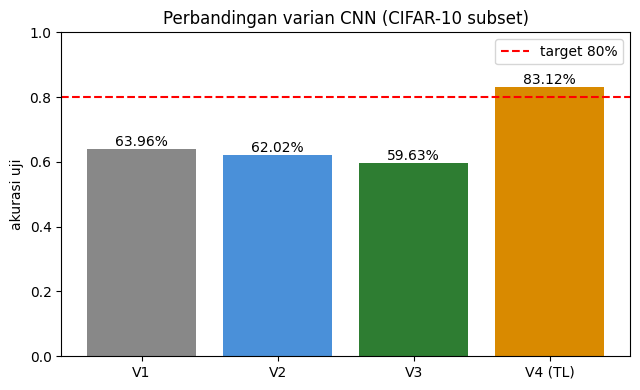

varian terbaik: V4 (TL) | >80%: True


In [6]:
plt.figure(figsize=(6.5, 4))
warna = ["#888", "#4a90d9", "#2e7d32", "#d98a00"]
plt.bar(tabel["varian"], tabel["test_acc"], color=warna)
plt.axhline(0.80, ls="--", c="red", label="target 80%")
for i, a in enumerate(tabel["test_acc"]):
    plt.text(i, a + .01, f"{a:.2%}", ha="center")
plt.ylim(0, 1); plt.ylabel("akurasi uji")
plt.title("Perbandingan varian CNN (CIFAR-10 subset)"); plt.legend()
plt.tight_layout(); plt.savefig(OUT / "perbandingan_varian.png", dpi=110); plt.show()
print("varian terbaik:", tabel.loc[tabel["test_acc"].idxmax(), "varian"],
      "| >80%:", bool((tabel["test_acc"] > 0.8).any()))

In [7]:
# bebas memori (fitur 20.000 x 1280 + base EfficientNetB0 masih menempel) sebelum melatih MNIST
del ftr, fte, ekstraktor, base, xt, xe, kepala
tf.keras.backend.clear_session(); gc.collect()
print("memori dibebaskan")

memori dibebaskan


# ## Bagian 3 — CNN MNIST
# Dataset dari `keras.datasets.mnist` (cache lokal `mnist.npz`, tanpa unduh ulang): 60.000 latih, 10.000 uji.

In [8]:
from tensorflow.keras.datasets import mnist
(mx, my), (mtx, mty) = mnist.load_data()
mx = (mx / 255.0)[..., None]; mtx = (mtx / 255.0)[..., None]
myc, mtyc = to_categorical(my, 10), to_categorical(mty, 10)
print("MNIST:", mx.shape, mtx.shape)

MNIST: (60000, 28, 28, 1) (10000, 28, 28, 1)


In [9]:
cm = Sequential([
    Input((28, 28, 1)),
    Conv2D(32, 3, activation="relu"), MaxPooling2D(2, 2),
    Conv2D(64, 3, activation="relu"), MaxPooling2D(2, 2),
    Flatten(), Dense(128, activation="relu"), Dropout(0.4), Dense(10, activation="softmax"),
])
cm.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
cm.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 26, 26, 32)        320       


 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         


 D)                                                              


... (7 outputs left out)

Total params: 225034 (879.04 KB)


Trainable params: 225034 (879.04 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [10]:
hm = cm.fit(mx, myc, batch_size=128, epochs=3, validation_split=0.1, verbose=2)
acc_mnist = float(cm.evaluate(mtx, mtyc, verbose=0)[1])
print(f"akurasi uji MNIST = {acc_mnist:.4f}")
np.savetxt(OUT / "akurasi_mnist.csv", np.array([[acc_mnist]]), header="test_acc", comments="")

Epoch 1/3


422/422 - 11s - loss: 0.2824 - accuracy: 0.9143 - val_loss: 0.0589 - val_accuracy: 0.9823 - 11s/epoch - 27ms/step


Epoch 2/3


422/422 - 11s - loss: 0.0904 - accuracy: 0.9729 - val_loss: 0.0517 - val_accuracy: 0.9848 - 11s/epoch - 25ms/step


Epoch 3/3


422/422 - 11s - loss: 0.0665 - accuracy: 0.9801 - val_loss: 0.0386 - val_accuracy: 0.9890 - 11s/epoch - 27ms/step


akurasi uji MNIST = 0.9879


jumlah salah klasifikasi: 121 dari 10000


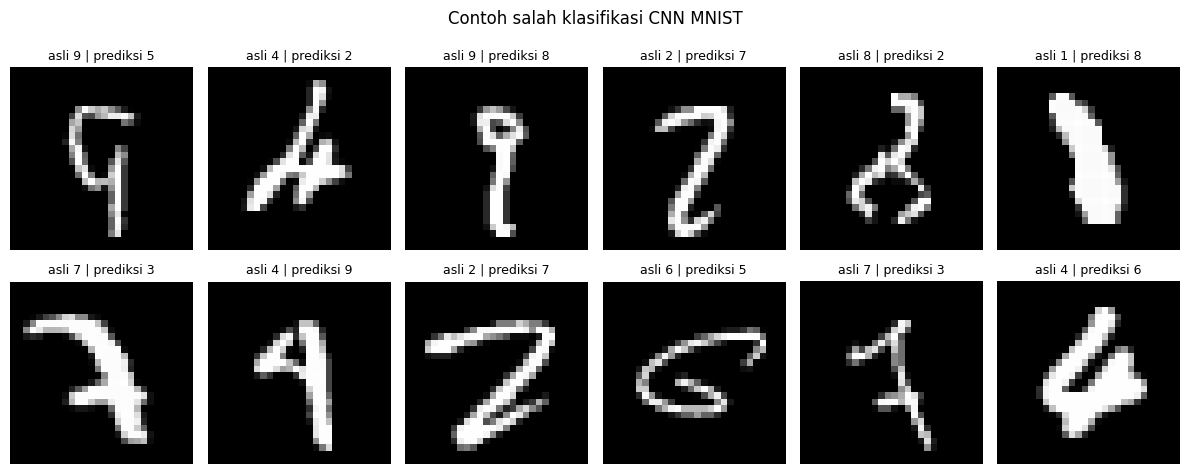

In [11]:
pred = cm.predict(mtx, verbose=0).argmax(1)
salah = np.where(pred != mty)[0]
print("jumlah salah klasifikasi:", len(salah), "dari", len(mty))

fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for ax, i in zip(axes.ravel(), salah[:12]):
    ax.imshow(mtx[i].squeeze(), cmap="gray")
    ax.set_title(f"asli {mty[i]} | prediksi {pred[i]}", fontsize=9); ax.axis("off")
plt.suptitle("Contoh salah klasifikasi CNN MNIST"); plt.tight_layout()
plt.savefig(OUT / "mnist_salah_klasifikasi.png", dpi=110); plt.show()

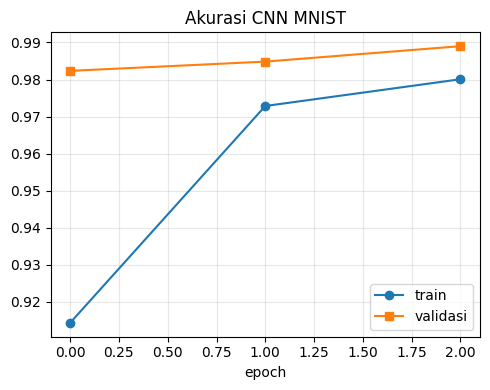

In [12]:
plt.figure(figsize=(5, 4))
plt.plot(hm.history["accuracy"], marker="o", label="train")
plt.plot(hm.history["val_accuracy"], marker="s", label="validasi")
plt.title("Akurasi CNN MNIST"); plt.xlabel("epoch"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "mnist_history.png", dpi=110); plt.show()